# SLM1 线性载频：MNIST 全息图、一级衍射与空间滤波

流程为：MNIST 图像 → SLM 复振幅全息图 → 傅里叶面 → 选取 +1 级 → 重建输入场。

研究重点是线性载频如何将目标一级与零级/共轭级分离，以及载频、滤波孔径和滤波器错位对效率与保真度的影响。实验参考 MATLAB 的 `D2NN_Experimental.m`：`gx = gy = 20e3 m^-1`、SLM 像素间距为 `8 um`。

## 使用原则

- 真实 SLM 模型：显示灰度全息图，傅里叶面同时含零级、+1 级与 -1 级，必须经过空间滤波。
- `U_target * exp(1j * carrier_phase)` 只是“已经选出的一级”的理想描述，不能用来研究零级泄漏。
- 对本 notebook 设定的 MNIST（目标相位 `Phi=0`），Arrizon 的 `f(A) sin(Phi + carrier)` 在 `gx=gy=0` 时退化为常数，不能编码振幅；无载频图只能作为平面镜/零级基线，**不存在可分离的 +1 级**。
- 选出的 +1 级仍带线性相位（输入倾角）。`demodulated` 场模拟后续光路已重新对准/去倾角；若实验未重新对准，则应保留该倾角。
- 本 notebook 测量的是前端的效率与场保真度，不是 MNIST 分类准确率。

In [9]:
from __future__ import annotations
from dataclasses import dataclass
from pathlib import Path
import struct
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['figure.dpi'] = 120
MNIST_RAW = Path.home() / 'data' / 'MNIST' / 'raw'
FX_PATH = Path('/home/chenlin/Project/Project/Structured_Light_classes/Structured_Light_classes/fx.mat')
OUTPUT_DIR = Path('slm1_carrier_results'); OUTPUT_DIR.mkdir(exist_ok=True)

@dataclass(frozen=True)
class OpticalConfig:
    pixel_pitch: float = 8e-6       # m, SLM1 calibration
    wavelength: float = 633e-9      # m; replace with the experimental laser value
    fourier_lens_f: float = 500e-3  # m; replace with the actual Fourier lens
    slm_shape: tuple[int, int] = (360, 640)  # (y, x), MATLAB input_grid_size
    illuminated_radius: float = 1.20e-3
    gaussian_waist: float = 0.90e-3
    filter_radius: float = 0.80e-3  # m in the Fourier plane; tune from measured spot size

cfg = OpticalConfig(); GX_REF = GY_REF = 20e3
def carrier_report(gx, gy):
    print(f'period x/y = {1/(gx*cfg.pixel_pitch):.2f}, {1/(gy*cfg.pixel_pitch):.2f} pixels')
    print(f'phase step x/y = {2*np.pi*gx*cfg.pixel_pitch:.3f}, {2*np.pi*gy*cfg.pixel_pitch:.3f} rad')
    print(f'+1 position = ({cfg.wavelength*cfg.fourier_lens_f*gx*1e3:.2f}, {cfg.wavelength*cfg.fourier_lens_f*gy*1e3:.2f}) mm')
    print(f'radial displacement = {cfg.wavelength*cfg.fourier_lens_f*np.hypot(gx,gy)*1e3:.2f} mm')
carrier_report(GX_REF, GY_REF)

period x/y = 6.25, 6.25 pixels
phase step x/y = 1.005, 1.005 rad
+1 position = (6.33, 6.33) mm
radial displacement = 8.95 mm


`gx = gy = 20e3 m^-1` 对应每轴 6.25 像素一个周期。在这里假设的 633 nm、500 mm 透镜下，+1 级位于 `(6.33, 6.33) mm`，径向偏移 `8.95 mm`。波长和焦距请按真实实验替换；`gx`、`gy` 单位必须是 `m^-1`，坐标 `X`、`Y` 单位必须是 m。

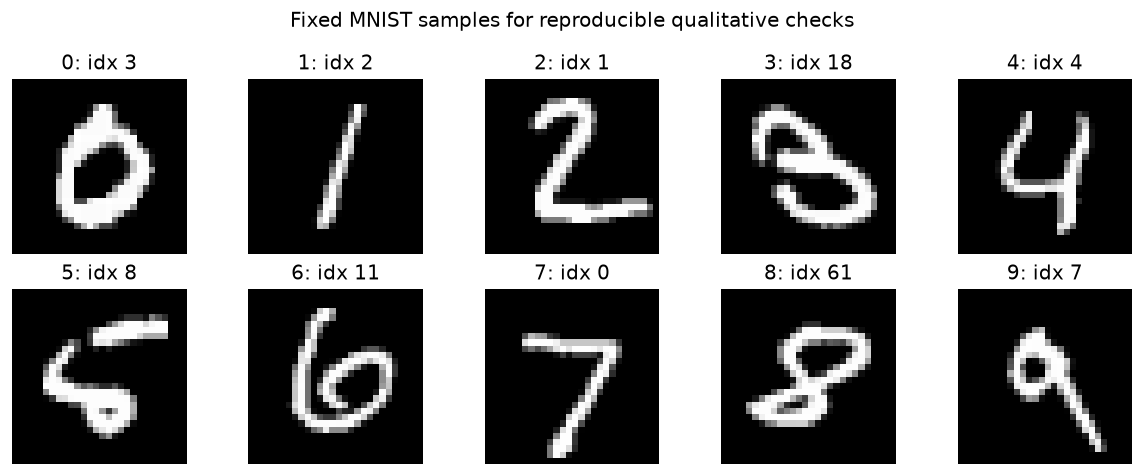

In [10]:
def read_idx_images(path: Path):
    with path.open('rb') as f:
        magic, n, rows, cols = struct.unpack('>IIII', f.read(16))
        if magic != 2051: raise ValueError(f'Bad image IDX magic: {magic}')
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows, cols)

def read_idx_labels(path: Path):
    with path.open('rb') as f:
        magic, n = struct.unpack('>II', f.read(8))
        if magic != 2049: raise ValueError(f'Bad label IDX magic: {magic}')
        return np.frombuffer(f.read(), dtype=np.uint8)[:n]

images = read_idx_images(MNIST_RAW / 't10k-images-idx3-ubyte')
labels = read_idx_labels(MNIST_RAW / 't10k-labels-idx1-ubyte')
indices = np.array([np.flatnonzero(labels == d)[0] for d in range(10)])
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for d, ax in enumerate(axes.flat):
    ax.imshow(images[indices[d]], vmin=0, vmax=255, cmap='gray'); ax.set_title(f'{d}: idx {indices[d]}'); ax.axis('off')
fig.suptitle('Fixed MNIST samples for reproducible qualitative checks'); fig.tight_layout()

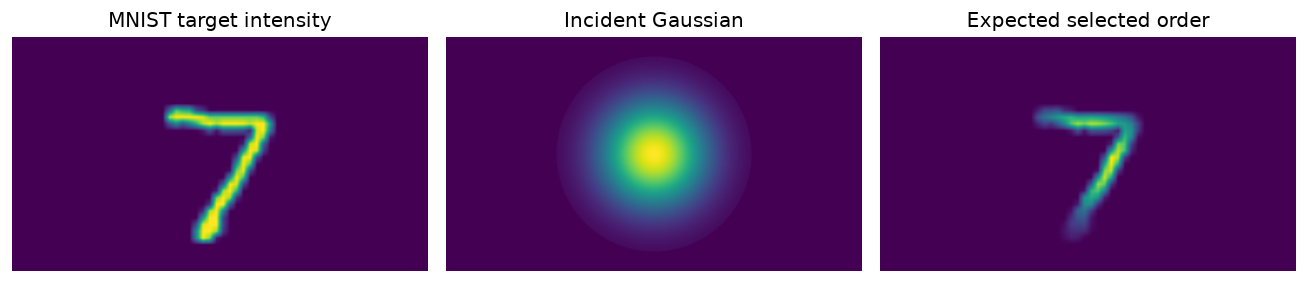

In [11]:
def resize_bilinear(image, shape):
    iy, ix = image.shape; oy, ox = shape
    ys = np.linspace(0, iy - 1, oy); xs = np.linspace(0, ix - 1, ox)
    y0 = np.floor(ys).astype(int); x0 = np.floor(xs).astype(int)
    y1 = np.minimum(y0 + 1, iy - 1); x1 = np.minimum(x0 + 1, ix - 1)
    wy = (ys - y0)[:, None]; wx = (xs - x0)[None, :]
    top = (1-wx)*image[y0][:, x0] + wx*image[y0][:, x1]
    bottom = (1-wx)*image[y1][:, x0] + wx*image[y1][:, x1]
    return (1-wy)*top + wy*bottom

def coordinates(cfg):
    ny, nx = cfg.slm_shape
    x = (np.arange(nx) - (nx-1)/2) * cfg.pixel_pitch
    y = (np.arange(ny) - (ny-1)/2) * cfg.pixel_pitch
    return x, y, *np.meshgrid(x, y, indexing='xy')

def mnist_field(image_u8, cfg, digit_width_px=280):
    ny, nx = cfg.slm_shape; _, _, X, Y = coordinates(cfg)
    intensity = np.zeros((ny, nx)); small = resize_bilinear(image_u8/255.0, (digit_width_px, digit_width_px))
    y0 = (ny-digit_width_px)//2; x0 = (nx-digit_width_px)//2
    intensity[y0:y0+digit_width_px, x0:x0+digit_width_px] = small
    aperture = X**2 + Y**2 <= cfg.illuminated_radius**2
    incident = np.exp(-(X**2 + Y**2)/cfg.gaussian_waist**2) * aperture
    # MNIST values are intensity. Therefore field amplitude is sqrt(I), not I.
    return np.sqrt(intensity)*aperture, incident, aperture

digit = 7
target, incident, aperture = mnist_field(images[indices[digit]], cfg)
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for axis, data, title in zip(ax, [np.abs(target)**2, incident**2, np.abs(target*incident)**2], ['MNIST target intensity', 'Incident Gaussian', 'Expected selected order']):
    axis.imshow(data); axis.set_title(title); axis.axis('off')
fig.tight_layout()

## MATLAB 等效 Arrizon 编码

MATLAB 的核心是 `Hol = f(A) * sin(Phi + 2*pi*(gx*X + gy*Y))`，随后逐帧归一化到 `[0, 1]`。`fx.mat` 是振幅—调制深度查找表。精确模式需要 `scipy` 来读取 `.mat`：`python -m pip install scipy`。`phase_only` 仅可用于检查衍射几何，不能用于复振幅效率结论。

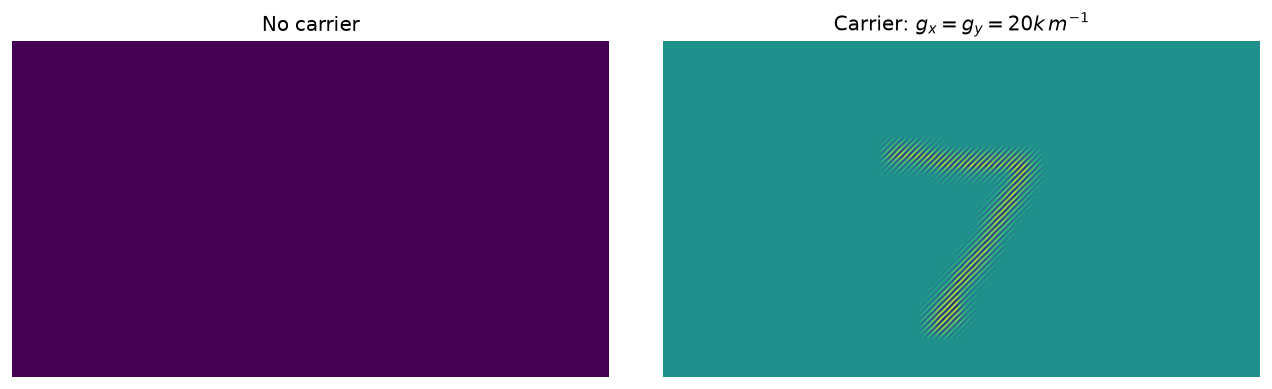

In [12]:
ENCODER = 'arrizon'  # 'arrizon' is the actual experiment; 'phase_only' is geometry-only debugging

def load_fx(path):
    try: from scipy.io import loadmat
    except ImportError as e: raise ImportError('Install scipy to use MATLAB-equivalent Arrizon encoding.') from e
    fx = np.asarray(loadmat(path)['fx']).squeeze().astype(float)
    if fx.ndim != 1 or len(fx) < 501: raise ValueError(f'Unexpected fx shape {fx.shape}')
    return fx

def hologram(field, gx, gy, *, encoder=ENCODER, fx=None):
    _, _, X, Y = coordinates(cfg); phase = np.angle(field) + 2*np.pi*(gx*X + gy*Y)
    if encoder == 'phase_only': return np.mod(phase, 2*np.pi)/(2*np.pi)
    if fx is None: raise ValueError('Arrizon encoding requires fx.mat.')
    amp = np.abs(field); amp = amp/amp.max() if amp.max() else amp
    # MATLAB fx(round(A/0.002 + 1)); convert the 1-based index to NumPy.
    lut_index = np.clip(np.floor(amp/0.002 + 0.5).astype(int), 0, len(fx)-1)
    raw = fx[lut_index] * np.sin(phase)
    span = raw.max() - raw.min()
    # Phi=0 and g=0 makes the Arrizon sine term identically zero. This is
    # not an amplitude hologram; model it as a flat SLM (zero-order baseline).
    return np.zeros_like(raw) if span <= np.finfo(float).eps else (raw-raw.min())/span

fx = load_fx(FX_PATH) if ENCODER == 'arrizon' else None
h_off, h_on = hologram(target, 0, 0, fx=fx), hologram(target, GX_REF, GY_REF, fx=fx)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for axis, data, title in zip(ax, [h_off, h_on], ['No carrier', r'Carrier: $g_x=g_y=20k\,m^{-1}$']):
    axis.imshow(data, vmin=0, vmax=1); axis.set_title(title); axis.axis('off')
fig.tight_layout()

In [13]:
def fft2c(u): return np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(u)))/np.sqrt(u.size)
def ifft2c(U): return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(U)))*np.sqrt(U.size)

def focal_coordinates(cfg):
    ny, nx = cfg.slm_shape
    xf = cfg.wavelength*cfg.fourier_lens_f*np.fft.fftshift(np.fft.fftfreq(nx, cfg.pixel_pitch))
    yf = cfg.wavelength*cfg.fourier_lens_f*np.fft.fftshift(np.fft.fftfreq(ny, cfg.pixel_pitch))
    return xf, yf, *np.meshgrid(xf, yf, indexing='xy')

def overlap(left, right):
    denom = np.linalg.norm(left.ravel())*np.linalg.norm(right.ravel())
    return 0.0 if denom == 0 else float(abs(np.vdot(left, right)/denom)**2)

def run_case(field, incident, aperture, gx, gy, offset_xy=(0., 0.)):
    _, _, X, Y = coordinates(cfg); h = hologram(field, gx, gy, fx=fx)
    # Replace this linear response once a measured grayscale-to-phase calibration is available.
    reflected = incident*aperture*np.exp(1j*2*np.pi*h)
    spectrum = fft2c(reflected); xf, yf, XF, YF = focal_coordinates(cfg)
    cx = cfg.wavelength*cfg.fourier_lens_f*gx + offset_xy[0]
    cy = cfg.wavelength*cfg.fourier_lens_f*gy + offset_xy[1]
    mask = (XF-cx)**2 + (YF-cy)**2 <= cfg.filter_radius**2
    reconstruction = ifft2c(spectrum*mask)
    demodulated = reconstruction*np.exp(-1j*2*np.pi*(gx*X + gy*Y))
    reference = incident*field*aperture
    separable_first_order = bool(gx != 0 or gy != 0)
    return dict(hologram=h, spectrum=spectrum, mask=mask, reconstruction=reconstruction, demodulated=demodulated,
                fidelity=overlap(reference, demodulated) if separable_first_order else np.nan,
                filtered_power=float(np.sum(abs(spectrum*mask)**2)/np.sum(abs(spectrum)**2)),
                separable_first_order=separable_first_order)

no_carrier = run_case(target, incident, aperture, 0, 0)
with_carrier = run_case(target, incident, aperture, GX_REF, GY_REF)
print(f"no carrier: filtered P={no_carrier['filtered_power']:.3f}; flat zero-order baseline, +1 fidelity undefined")
print(f"with carrier: filtered P={with_carrier['filtered_power']:.3f}, +1 field fidelity={with_carrier['fidelity']:.3f}")

no carrier: filtered P=0.997; flat zero-order baseline, +1 fidelity undefined
with carrier: filtered P=0.076, +1 field fidelity=0.930


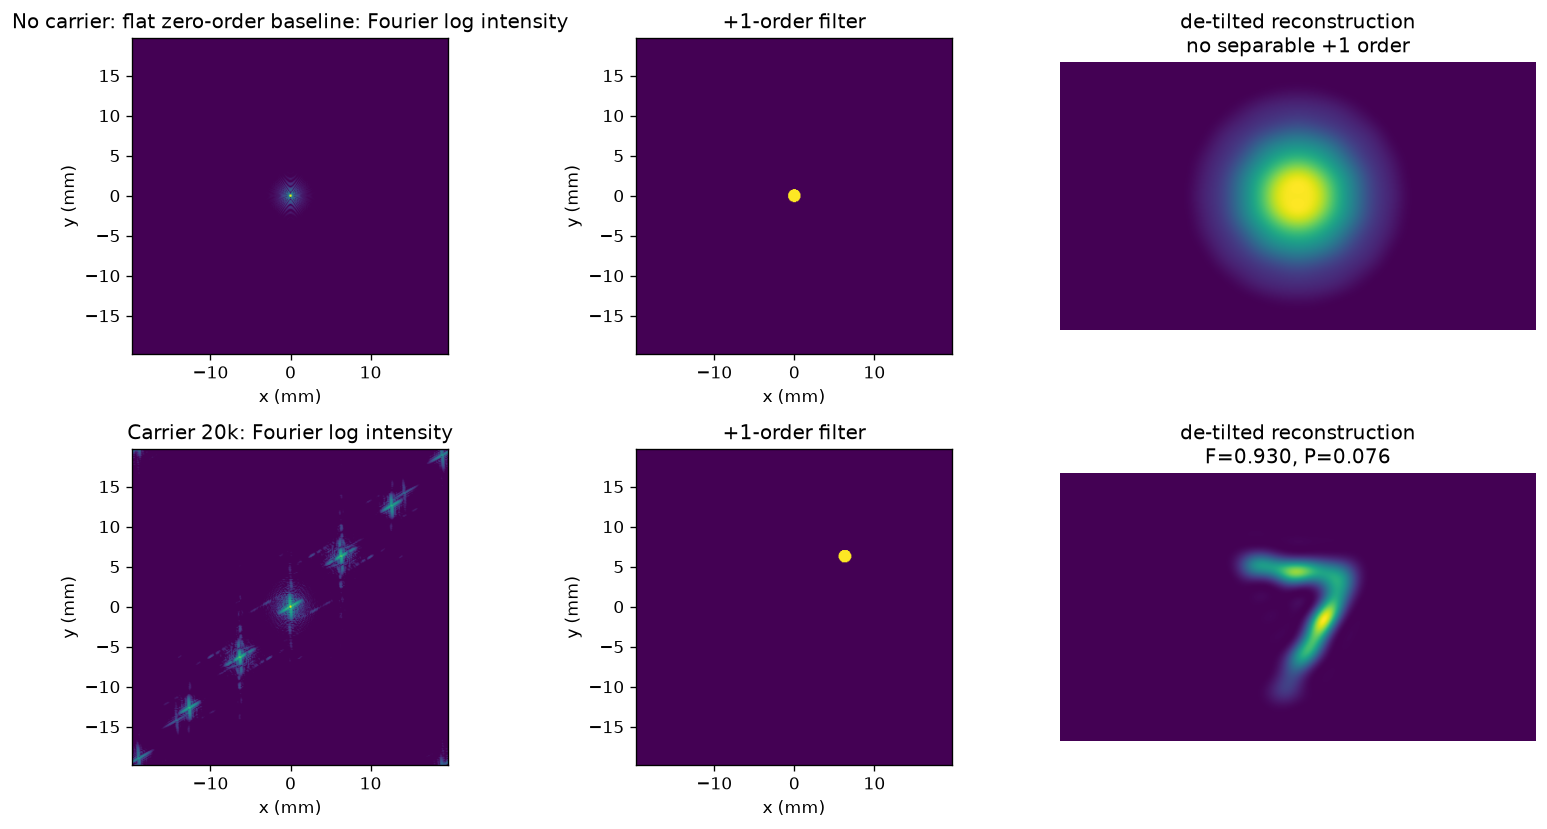

In [14]:
def log_intensity(u):
    I = abs(u)**2; return np.log10(I/I.max() + 1e-7)
xf, yf, _, _ = focal_coordinates(cfg); extent = [xf[0]*1e3, xf[-1]*1e3, yf[0]*1e3, yf[-1]*1e3]
fig, ax = plt.subplots(2, 3, figsize=(13, 7))
for row, (name, result) in enumerate([('No carrier: flat zero-order baseline', no_carrier), ('Carrier 20k', with_carrier)]):
    ax[row,0].imshow(log_intensity(result['spectrum']), extent=extent, origin='lower', vmin=-6, vmax=0)
    ax[row,0].set(title=f'{name}: Fourier log intensity', xlabel='x (mm)', ylabel='y (mm)')
    ax[row,1].imshow(result['mask'], extent=extent, origin='lower'); ax[row,1].set(title='+1-order filter', xlabel='x (mm)', ylabel='y (mm)')
    ax[row,2].imshow(abs(result['demodulated'])**2)
    metric = 'no separable +1 order' if not result['separable_first_order'] else f"F={result['fidelity']:.3f}, P={result['filtered_power']:.3f}"
    ax[row,2].set(title=f'de-tilted reconstruction\n{metric}')
    ax[row,2].axis('off')
fig.tight_layout()
# For g=0 the circular filter is centred on the zero order; it cannot isolate +1.

## 扫描载频与滤波器错位

先比较载频，不应只做开/关：`6.25 px` 是实验值，`8–12 px` 是较保守的相邻候选，`4–5 px` 用于观察像素采样过粗时的趋势。接着在固定实验载频下扫描物理滤波孔中心误差，得到对准容差。`​filter_radius` 需按实测 +1 级光斑大小重新设置。

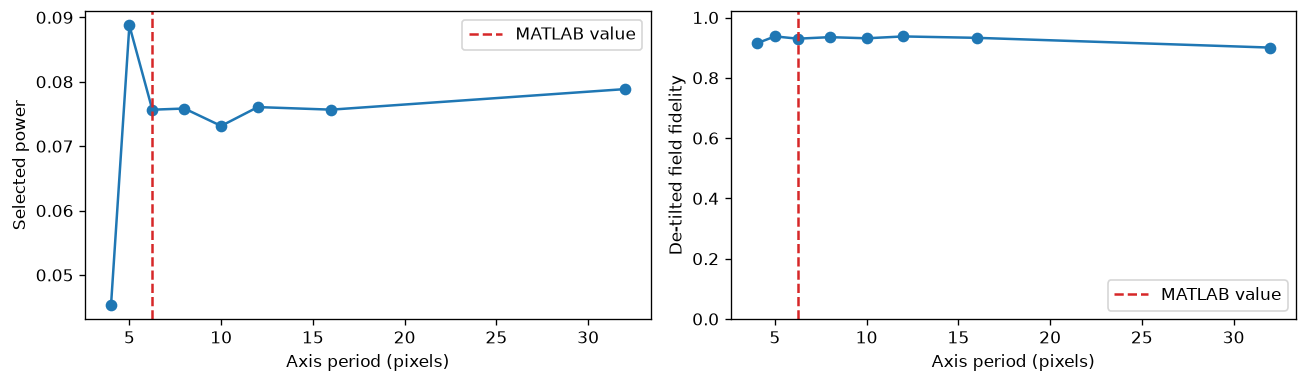

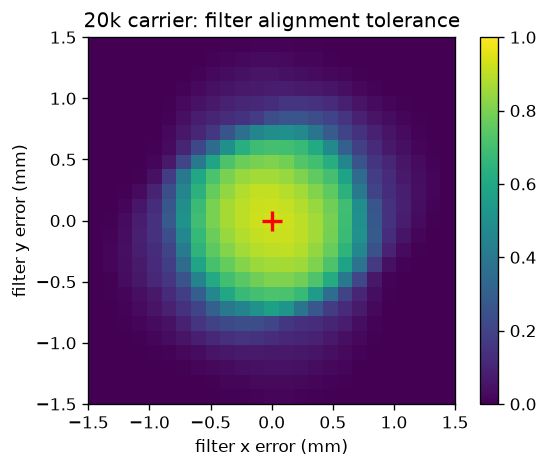

In [15]:
periods = np.array([np.inf, 32, 16, 12, 10, 8, 6.25, 5, 4.])
scan = []
for period in periods:
    g = 0. if np.isinf(period) else 1/(period*cfg.pixel_pitch)
    result = run_case(target, incident, aperture, g, g)
    scan.append((period, result['filtered_power'], result['fidelity']))
finite = np.isfinite(periods)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(periods[finite], [r[1] for r in scan if np.isfinite(r[0])], 'o-'); ax[0].set(xlabel='Axis period (pixels)', ylabel='Selected power')
ax[1].plot(periods[finite], [r[2] for r in scan if np.isfinite(r[0])], 'o-'); ax[1].set(xlabel='Axis period (pixels)', ylabel='De-tilted field fidelity', ylim=(0,1.02))
for axis in ax: axis.axvline(6.25, color='tab:red', ls='--', label='MATLAB value'); axis.legend()
fig.tight_layout()

offset_mm = np.linspace(-1.5, 1.5, 25); fidelity = np.empty((len(offset_mm), len(offset_mm)))
for iy, dy in enumerate(offset_mm):
    for ix, dx in enumerate(offset_mm):
        fidelity[iy, ix] = run_case(target, incident, aperture, GX_REF, GY_REF, (dx*1e-3, dy*1e-3))['fidelity']
fig, ax = plt.subplots(figsize=(5,4)); im = ax.imshow(fidelity, origin='lower', extent=[*offset_mm[[0,-1]], *offset_mm[[0,-1]]], vmin=0, vmax=1)
ax.plot(0,0,'r+',ms=12,mew=2); ax.set(xlabel='filter x error (mm)', ylabel='filter y error (mm)', title='20k carrier: filter alignment tolerance'); fig.colorbar(im, ax=ax); fig.tight_layout()

## 可选：MNIST 测试集统计

在固定载频与光学参数下，对测试集抽样统计前端保真度和选级功率。先用 100 张验证流程；确认滤波半径、SLM 相位响应和光束参数后再扩大。

100-image selected power: 0.0912 ± 0.0185
100-image field fidelity: 0.9190 ± 0.0221


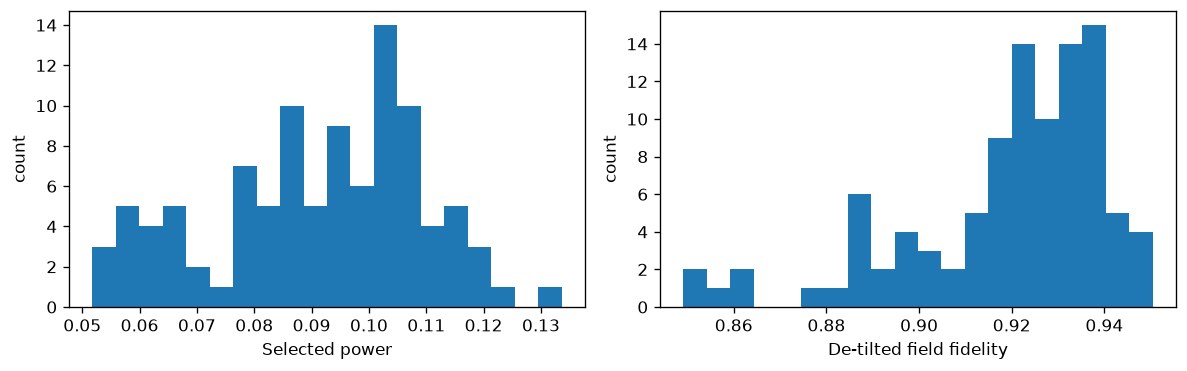

In [16]:
rng = np.random.default_rng(7); sample = rng.choice(len(images), size=100, replace=False)
powers, fidelities = [], []
for i in sample:
    current_target, current_incident, current_aperture = mnist_field(images[i], cfg)
    result = run_case(current_target, current_incident, current_aperture, GX_REF, GY_REF)
    powers.append(result['filtered_power']); fidelities.append(result['fidelity'])
print(f'100-image selected power: {np.mean(powers):.4f} ± {np.std(powers):.4f}')
print(f'100-image field fidelity: {np.mean(fidelities):.4f} ± {np.std(fidelities):.4f}')
fig, ax = plt.subplots(1,2,figsize=(10,3.2))
ax[0].hist(powers, bins=20); ax[0].set(xlabel='Selected power', ylabel='count')
ax[1].hist(fidelities, bins=20); ax[1].set(xlabel='De-tilted field fidelity', ylabel='count')
fig.tight_layout()

## 实验前结论清单

1. 主对照组固定为 MATLAB 实验值 `gx = gy = 20e3 m^-1`；使用 `8–12 px` 周期作保守邻近对照。
2. 真实傅里叶面先确定 +1 级中心和尺寸，再设定滤波孔中心/半径。
3. 取得 SLM 灰度—相位标定后，替换 `exp(1j*2*pi*hologram)` 的线性假设。
4. 若一级没有被后续光路重新对准，必须将其残余倾角保留为后续系统的输入。
5. 若以后做端到端 MNIST 分类，需要单独定义任意图像输入、10 个输出探测区和训练损失；已有 LG 模式分拣结果不可直接复用。